# Batched parallel inference

Verify Bioscrape's general batched multiprocessing method on a synthetic
two-species reaction network. Check built-in and custom priors, numerical
agreement, prior rejection, persistent worker setup, and timing on identical
parameter proposals. All observations are generated here.

Install this Bioscrape checkout in the Python environment used by the kernel.
Keep `batched_parallel_checks.py` beside this notebook: its importable worker
functions support Windows multiprocessing. Relevant settings are defined in
each cell where they are used.

In [1]:
import os
for name in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[name] = "1"

from pathlib import Path
import inspect
import multiprocessing
import pickle
import platform
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import bioscrape
from bioscrape.inference import py_inference
from bioscrape.inference_setup import InferenceSetup
from bioscrape.pid_interfaces import PIDInterface
from bioscrape.parallel_inference import _initialize_likelihood_worker
from batched_parallel_checks import make_setup, coupled_prior, coupled_prior_batch, proposal_batches, benchmark_batch_methods

RESULTS_DIR = Path("batched_parallel_results")
RESULTS_DIR.mkdir(exist_ok=True)
assert hasattr(InferenceSetup, "_cost_function_batch")
print("Python:", sys.executable)
print("Bioscrape:", bioscrape.__version__)
print("Inference implementation:", inspect.getfile(InferenceSetup))
print("Hardware:", platform.processor(), "; logical CPUs:", os.cpu_count())
assert hasattr(PIDInterface, "get_log_prior_batch")

Python: C:\Users\ayush\.conda\envs\biotools\python.exe
Bioscrape: 1.4.2.dev32+gce3dd66b1.d20260925
Inference implementation: C:\Users\ayush\Box\Research\hierarchical-validation-id\bioscrape\bioscrape\inference_setup.py
Hardware: Intel64 Family 6 Model 204 Stepping 2, GenuineIntel ; logical CPUs: 16


## Synthetic model and observations

The reactions produce X, degrade X, produce Y from X, and degrade Y.
Infer `kprod` and `kdeg`; vary the fixed translation rate across conditions.
The joint prior below adds a finite penalty and rejects some combinations.
It uses the same callback interface as a custom prior containing a GP.

,distribution,lower,upper
kprod,log-uniform,0.1,20.0
kdeg,log-uniform,0.01,2.0


def coupled_prior(params):
    """An example joint log prior, with rejection and a finite contribution."""
    if params['kprod'] > 18*params['kdeg']:
        return -np.inf
    return -.01*(params['kprod']-5.)**2



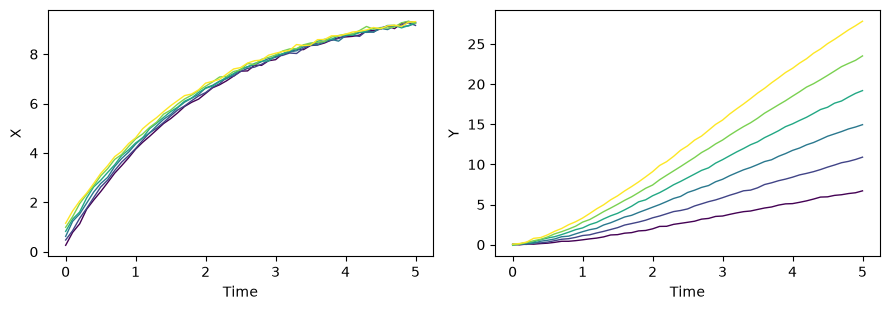

In [2]:
N_CONDITIONS = 6
N_REPLICATES = 3
N_TIMEPOINTS = 51

setup = make_setup(N_CONDITIONS, N_REPLICATES, N_TIMEPOINTS)
display(pd.DataFrame(setup.prior, index=["distribution", "lower", "upper"]).T)
print(inspect.getsource(coupled_prior))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)
for index, frame in enumerate(setup.exp_data[::N_REPLICATES]):
    color = plt.cm.viridis(index/(N_CONDITIONS-1))
    for ax, species in zip(axes, ("X", "Y")):
        ax.plot(frame.time, frame[species], color=color, lw=1)
        ax.set(xlabel="Time", ylabel=species)
fig.tight_layout()
plt.show()

## Every prior type uses the same evaluation route

The separated prior and likelihood must sum to the scalar log posterior.
This also tests finite positive log-prior contributions.

In [3]:
PRIOR_CHECK_PARAMETERS = np.array([.3, .5])
prior_specs = [
    ["uniform", .01, 2.], ["gaussian", .4, .1], ["exponential", 2.],
    ["gamma", 2., 4.], ["beta", 2., 4.], ["log-uniform", .01, 2.],
    ["log-gaussian", -1., 1.], ["custom", lambda name, value: -.5*value**2],
]
prior_checks = []
for spec in prior_specs:
    example = make_setup(1, 1, 9)
    example.prior = {name: spec for name in example.params_to_estimate}
    example.custom_joint_prior = lambda params: .75
    example.setup_cost_function()
    interface = example.pid_interface
    lp = interface.get_log_prior(PRIOR_CHECK_PARAMETERS)
    ll = interface.get_log_likelihood(PRIOR_CHECK_PARAMETERS)
    scalar = interface.get_likelihood_function(PRIOR_CHECK_PARAMETERS)
    np.testing.assert_allclose(scalar, lp+ll, rtol=1e-12, atol=1e-12)
    prior_checks.append(dict(prior=spec[0], log_prior=lp, difference=scalar-(lp+ll)))
display(pd.DataFrame(prior_checks))

,prior,log_prior,difference
0,uniform,-0.626269,0.0
1,gaussian,2.517293,0.0
2,exponential,0.536294,0.0
3,gamma,1.198057,0.0
4,beta,1.694878,0.0
5,log-uniform,-0.687659,0.0
6,log-gaussian,0.741361,0.0
7,custom,0.580000,0.0


## Custom priors stay in the parent process

Use local callback functions, which ordinary multiprocessing cannot pickle.
Their finite contributions are included once; rejected tuples receive
negative infinity. A tuple outside a parameter prior also skips the joint
callback. The final benchmark counts the actual likelihood calls.

In [4]:
N_PROCESSES = 2
TEST_PARAMETERS = np.array([[5., .5], [9., .3], [25., .5]])

example = make_setup(2, 1, 15)
parent_pid = os.getpid()
callback_calls = []
def local_parameter_prior(name, value):
    assert os.getpid() == parent_pid
    return -.01*value if value <= 20 else -np.inf
def local_joint_prior(params):
    assert os.getpid() == parent_pid
    callback_calls.append(params.copy())
    return .25 if params["kprod"] < 18*params["kdeg"] else -np.inf
example.prior["kprod"] = ["custom", local_parameter_prior]
example.custom_joint_prior = local_joint_prior
example.setup_cost_function()
config = example._get_likelihood_worker_config()
pickle.dumps(config)
with multiprocessing.get_context("spawn").Pool(
        N_PROCESSES, _initialize_likelihood_worker, (config,)) as pool:
    values = example._cost_function_batch(TEST_PARAMETERS, pool)
assert len(callback_calls) == 2
assert np.isfinite(values[0]) and np.isneginf(values[1:]).all()
parameter_lp = PIDInterface(example.params_to_estimate, example.M, example.prior).get_log_prior(TEST_PARAMETERS[0])
expected = parameter_lp + .25 + example.pid_interface.get_log_likelihood(TEST_PARAMETERS[0])
np.testing.assert_allclose(values[0], expected, rtol=1e-12, atol=1e-12)
display(pd.DataFrame({"kprod": TEST_PARAMETERS[:, 0], "kdeg": TEST_PARAMETERS[:, 1], "log_posterior": values}))
print("Local custom callbacks stayed in parent PID", parent_pid)
print("Joint-prior calls:", len(callback_calls), "; expected: 2")

,kprod,kdeg,log_posterior
0,5.0,0.5,-43.188275
1,9.0,0.3,-inf
2,25.0,0.5,-inf


Local custom callbacks stayed in parent PID 49100
Joint-prior calls: 2 ; expected: 2


## Batch custom joint priors

The batch callback receives one array per parameter and returns one log-prior
contribution per proposal. Parameter-wise priors run first. Verify a single
parent-process callback, preserved ordering, matching scalar posterior values,
and no callback for empty or fully rejected batches. The sampler checks below
also supply scalar and batch implementations of the same prior.

In [5]:
N_PROCESSES = 2
TEST_PARAMETERS = np.array([[5., .5], [9., .3], [25., .5], [4., .4]])

example = make_setup(2, 1, 15)
parent_pid = os.getpid()
batch_calls = []

def local_batch_joint_prior(params):
    assert os.getpid() == parent_pid
    batch_calls.append({name: values.copy() for name, values in params.items()})
    return coupled_prior_batch(params)

example.custom_joint_prior_batch = local_batch_joint_prior
example.setup_cost_function()
expected = np.array([example.cost_function(row) for row in TEST_PARAMETERS])
config = example._get_likelihood_worker_config()
assert "custom_joint_prior_batch" not in config["likelihood_kwargs"]
pickle.dumps(config)
with multiprocessing.get_context("spawn").Pool(
        N_PROCESSES, _initialize_likelihood_worker, (config,)) as pool:
    actual = example._cost_function_batch(TEST_PARAMETERS, pool)
np.testing.assert_allclose(actual, expected, rtol=1e-12, atol=1e-12)
assert len(batch_calls) == 1
np.testing.assert_array_equal(batch_calls[0]["kprod"], [5., 9., 4.])
example.pid_interface.get_log_prior_batch(np.empty((0, 2)))
example.pid_interface.get_log_prior_batch(np.array([[25., .5]]))
assert len(batch_calls) == 1

display(pd.DataFrame({"kprod": TEST_PARAMETERS[:, 0],
                      "kdeg": TEST_PARAMETERS[:, 1],
                      "scalar_log_posterior": expected,
                      "batch_log_posterior": actual}))
print("Batch joint-prior calls:", len(batch_calls), "; proposals supplied:", len(batch_calls[0]["kprod"]))
print("Identical scalar and batch log posterior values; callback stayed in parent PID", parent_pid)

,kprod,kdeg,scalar_log_posterior,batch_log_posterior
0,5.0,0.5,-46.665102,-46.665102
1,9.0,0.3,-inf,-inf
2,25.0,0.5,-inf,-inf
3,4.0,0.4,-44.553073,-44.553073


Batch joint-prior calls: 1 ; proposals supplied: 3
Identical scalar and batch log posterior values; callback stayed in parent PID 49100


## End-to-end deterministic sampler agreement

Run the public `py_inference` API in serial, ordinary multiprocessing and
batched multiprocessing modes. Each run uses the same joint prior,
initial walker array and sampler seed. The assertions compare every saved
walker tuple and log posterior. These short runs check implementation;
they are not posterior-convergence runs.

In [6]:
N_PROCESSES = 2
NWALKERS = 16
NSTEPS = 40
RANDOM_SEED = 2026

initial_walkers = np.array([5., .5])*(1+.02*np.random.default_rng(RANDOM_SEED).normal(size=(NWALKERS, 2)))
sampler_rows, chains, log_probabilities = [], {}, {}
for method in ("serial", "pool", "batched"):
    example = make_setup(2, 1, 15)
    np.random.seed(RANDOM_SEED)
    started = time.perf_counter()
    sampler, inference = py_inference(
        Model=example.M, exp_data=example.exp_data, measurements=["X", "Y"],
        time_column="time", params_to_estimate=example.params_to_estimate,
        initial_conditions=example.initial_conditions,
        parameter_conditions=example.parameter_conditions,
        prior=example.prior, custom_joint_prior=coupled_prior,
        custom_joint_prior_batch=coupled_prior_batch,
        nwalkers=NWALKERS, nsteps=NSTEPS, init_seed=initial_walkers.copy(),
        parallel=method != "serial", n_processes=N_PROCESSES,
        parallel_method="batched" if method == "batched" else "pool",
        plot_show=False, printout=False, progess=False,
        filename_csv=str(RESULTS_DIR / f"{method}_samples.csv"),
        filename_txt=str(RESULTS_DIR / f"{method}_progress.txt"))
    seconds = time.perf_counter()-started
    chains[method], log_probabilities[method] = sampler.get_chain(), sampler.get_log_prob()
    np.testing.assert_array_equal(chains[method], chains["serial"])
    np.testing.assert_allclose(log_probabilities[method], log_probabilities["serial"], rtol=1e-12, atol=1e-12)
    sampler_rows.append(dict(method=method, total_seconds=seconds,
        mean_acceptance=float(sampler.acceptance_fraction.mean()),
        max_chain_difference=float(np.max(np.abs(chains[method]-chains["serial"]))),
        max_log_posterior_difference=float(np.max(np.abs(log_probabilities[method]-log_probabilities["serial"])))))
sampler_results = pd.DataFrame(sampler_rows)
display(sampler_results)
sampler_results.to_csv(RESULTS_DIR / "sampler_checks.csv", index=False)

,method,total_seconds,mean_acceptance,max_chain_difference,max_log_posterior_difference
0,serial,0.200744,0.696875,0.0,0.0
1,pool,3.931063,0.696875,0.0,0.0
2,batched,3.600720,0.696875,0.0,0.0


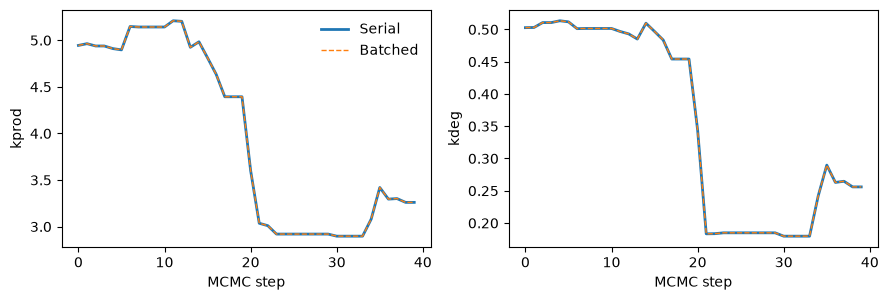

In [7]:
WALKER_TO_SHOW = 0

fig, axes = plt.subplots(1, 2, figsize=(9, 3.1))
for index, ax in enumerate(axes):
    ax.plot(chains["serial"][:, WALKER_TO_SHOW, index], label="Serial", lw=2)
    ax.plot(chains["batched"][:, WALKER_TO_SHOW, index], label="Batched", ls="--", lw=1)
    ax.set(xlabel="MCMC step", ylabel=("kprod", "kdeg")[index])
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

## Stochastic inference

Exercise the same batched method with the native stochastic likelihood.
Stochastic simulation draws can differ with worker scheduling, so this
check verifies successful finite likelihood evaluations and saved chains.

In [8]:
N_PROCESSES = 2
NWALKERS = 12
NSTEPS = 4
RANDOM_SEED = 2026
N_SIMULATIONS = 2

example = make_setup(1, 1, 9)
example.set_sim_type("stochastic")
example.set_N_simulations(N_SIMULATIONS)
example.set_parallel(True)
example.set_nwalkers(NWALKERS)
example.set_nsteps(NSTEPS)
example.set_init_seed(np.array([5., .5])*(1+.02*np.random.default_rng(RANDOM_SEED).normal(size=(NWALKERS, 2))))
np.random.seed(RANDOM_SEED)
stochastic_sampler = example.run_mcmc(
    parallel_method="batched", n_processes=N_PROCESSES, printout=False, progess=False,
    filename_csv=str(RESULTS_DIR / "stochastic_samples.csv"),
    filename_txt=str(RESULTS_DIR / "stochastic_progress.txt"))
assert stochastic_sampler.get_chain().shape == (NSTEPS, NWALKERS, 2)
assert np.isfinite(stochastic_sampler.get_log_prob()).all()
print("Stochastic chain shape:", stochastic_sampler.get_chain().shape)
print("All saved stochastic log posteriors are finite.")

Stochastic chain shape: (4, 12, 2)
All saved stochastic log posteriors are finite.


## Count and time actual worker setup

Replay identical proposal batches with the same model, data and priors.
The ordinary-pool replay uses its default chunk size, transporting the
inference object with each chunk. The batched replay calls the production
batch evaluator with persistent likelihood workers and one tuple per task.
Importable instrumentation in `batched_parallel_checks.py` counts setup
and likelihood calls without inserting artificial delays.

Compare a design entirely inside the parameter bounds and one with 50%
outside. The joint prior also rejects some points. Alternate method order
between repeats. Pool startup ends when every worker is ready and is
reported separately. `summed_worker_setup_seconds` adds the measured setup
durations across workers; `batch_seconds` is the parent-observed wall time.

In [9]:
N_PROCESSES = 2
N_BATCHES = 64
BATCH_SIZE = 64
N_REPEATS = 3
RANDOM_SEED = 2026
OUTSIDE_FRACTIONS = (0., .5)

benchmark_parts = []
for fraction in OUTSIDE_FRACTIONS:
    batches = proposal_batches(N_BATCHES, BATCH_SIZE, fraction, RANDOM_SEED)
    measured = benchmark_batch_methods(batches, N_PROCESSES, N_REPEATS)
    measured["outside_parameter_bounds_fraction"] = fraction
    benchmark_parts.append(measured)
benchmark_results = pd.concat(benchmark_parts, ignore_index=True)
benchmark_results.to_csv(RESULTS_DIR / "batch_benchmark.csv", index=False)
display(benchmark_results)

,method,repeat,processes,proposals,likelihood_calls,worker_setups,summed_worker_setup_seconds,startup_seconds,batch_seconds,startup_plus_batch_seconds,outside_parameter_bounds_fraction
0,pool,1,2,4096,3104,512,1.968359,3.434218,7.117383,10.551601,0.0
1,batched,1,2,4096,3104,2,0.000933,4.280002,5.207307,9.487308,0.0
2,batched,2,2,4096,3104,2,0.000946,3.547560,4.984449,8.532009,0.0
3,pool,2,2,4096,3104,512,2.063107,3.616925,7.279054,10.895979,0.0
4,pool,3,2,4096,3104,512,1.858432,3.852987,6.498730,10.351718,0.0
5,batched,3,2,4096,3104,2,0.000980,3.908504,5.184835,9.093339,0.0
6,pool,1,2,4096,1535,512,1.955213,3.492876,4.404571,7.897446,0.5
7,batched,1,2,4096,1535,2,0.001325,3.969455,2.584019,6.553474,0.5
8,batched,2,2,4096,1535,2,0.001008,3.737787,2.492611,6.230398,0.5
9,pool,2,2,4096,1535,512,1.961482,3.460583,4.452195,7.912777,0.5


worker_setups  likelihood_calls  \
outside_parameter_bounds_fraction method                                     
0.0                               batched            2.0            3104.0   
                                  pool             512.0            3104.0   
0.5                               batched            2.0            1535.0   
                                  pool             512.0            1535.0   

                                           summed_worker_setup_seconds  \
outside_parameter_bounds_fraction method                                 
0.0                               batched                     0.000946   
                                  pool                        1.968359   
0.5                               batched                     0.001325   
                                  pool                        1.955213   

                                           startup_seconds  batch_seconds  \
outside_parameter_bounds_fraction method                                    
0.0                               batched         3.908504       5.184835   
                                  pool            3.616925       7.117383   
0.5                               batched         3.737787       2.584019   
                                  pool            3.460583       4.452195   

                                           startup_plus_batch_seconds  
outside_parameter_bounds_fraction method                               
0.0                               batched                    9.093339  
                                  pool                      10.551601  
0.5                               batched                    6.230398  
                                  pool                       7.897446

,outside_parameter_bounds_fraction,setup_time_reduction_pct,repeated_batch_time_reduction_pct,startup_plus_batch_time_reduction_pct
0,0.0,99.951960,27.152504,13.820291
1,0.5,99.932222,41.960786,21.108699


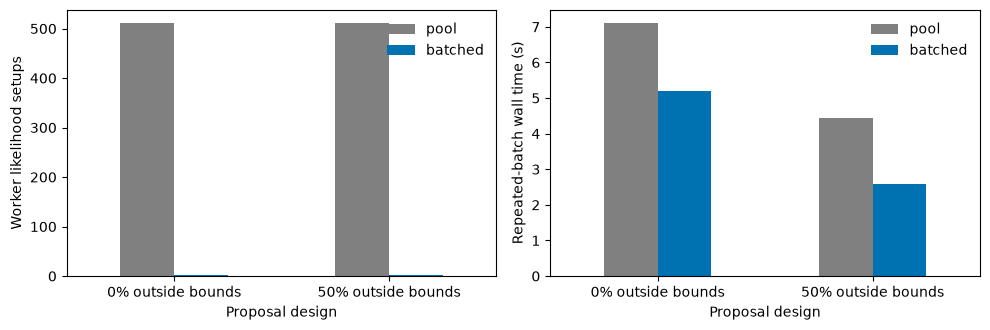

In [10]:
SUMMARY_COLUMNS = ["worker_setups", "likelihood_calls", "summed_worker_setup_seconds",
                   "startup_seconds", "batch_seconds", "startup_plus_batch_seconds"]

benchmark_summary = benchmark_results.groupby(
    ["outside_parameter_bounds_fraction", "method"])[SUMMARY_COLUMNS].median()
display(benchmark_summary)
improvements = []
for fraction in OUTSIDE_FRACTIONS:
    group = benchmark_summary.loc[fraction]
    improvements.append(dict(outside_parameter_bounds_fraction=fraction,
        setup_time_reduction_pct=100*(1-group.loc["batched", "summed_worker_setup_seconds"]/group.loc["pool", "summed_worker_setup_seconds"]),
        repeated_batch_time_reduction_pct=100*(1-group.loc["batched", "batch_seconds"]/group.loc["pool", "batch_seconds"]),
        startup_plus_batch_time_reduction_pct=100*(1-group.loc["batched", "startup_plus_batch_seconds"]/group.loc["pool", "startup_plus_batch_seconds"])))
improvements = pd.DataFrame(improvements)
display(improvements)
improvements.to_csv(RESULTS_DIR / "time_reductions.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, column, ylabel in zip(axes, ("worker_setups", "batch_seconds"),
                             ("Worker likelihood setups", "Repeated-batch wall time (s)")):
    table = benchmark_summary[column].unstack("method")[["pool", "batched"]]
    table.index = [f"{100*f:.0f}% outside bounds" for f in table.index]
    table.plot.bar(ax=ax, color=[".5", "#0072B2"], rot=0)
    ax.set(xlabel="Proposal design", ylabel=ylabel)
    ax.legend(title=None, frameon=False)
fig.tight_layout()
plt.show()

The assertions establish numerical agreement, parent-process prior
evaluation, identical likelihood counts on identical proposals, and one
likelihood setup per resident worker. The tables distinguish setup savings,
repeated-batch wall time, and total time including worker startup. Negative
time-reduction percentages mean the measured batched run took longer.
The measured time benefit depends on model cost, batch size and hardware.